In [ ]:
import torch

print(torch.__version__)

if torch.cuda.is_available():
    print(f"CUDA/ROCm GPU: {torch.cuda.get_device_name(0)}")

elif torch.xpu.is_available():
    print(f"Intel GPU: {torch.xpu.get_device_name(0)}")

elif torch.backends.mps.is_available():
    print("Apple Silicon GPU")

else:
    print("Only CPU")

In [ ]:
from reasoning_from_scratch.qwen3 import download_qwen3_small

download_qwen3_small(kind="base", tokenizer_only=True, out_dir="qwen3")

In [ ]:
from pathlib import Path
from reasoning_from_scratch.qwen3 import Qwen3Tokenizer

tokenizer_path = Path("qwen3") / "tokenizer-base.json"
tokenizer = Qwen3Tokenizer(tokenizer_file_path=tokenizer_path)

In [ ]:
prompt = "Explain large language models"
input_token_ids_list = tokenizer.encode(prompt)
print(input_token_ids_list)

In [ ]:
for i in input_token_ids_list:
    print(f"{i} --> {tokenizer.decode([i])}")

In [ ]:
input_original_text = tokenizer.decode(input_token_ids_list)
print(input_original_text)

In [ ]:
download_qwen3_small(kind="base", tokenizer_only=False, out_dir="qwen3")

In [ ]:
import torch

def get_device(enable_tensor_cores=True):
    if torch.cuda.is_available():
        device = torch.device("cuda")
        print("Using NVIDIA CUDA GPU")

        if enable_tensor_cores:
            major, minor = map(int, torch.__version__.split(".")[:2])
            # PyTorch 2.9 and 2.10 still read the legacy TF32 setting in torch.compile.
            # See https://github.com/pytorch/pytorch/issues/166387
            # and https://github.com/rasbt/reasoning-from-scratch/issues/256
            if (major, minor) >= (2, 11):
                torch.backends.cuda.matmul.fp32_precision = "tf32"
                torch.backends.cudnn.conv.fp32_precision = "tf32"
            else:
                torch.backends.cuda.matmul.allow_tf32 = True
                torch.backends.cudnn.allow_tf32 = True

    elif torch.backends.mps.is_available():
        device = torch.device("mps")
        print("Using Apple Silicon GPU (MPS)")

    elif torch.xpu.is_available():
        device = torch.device("xpu")
        print("Using Intel GPU")

    else:
        device = torch.device("cpu")
        print("Using CPU")

    return device

device = get_device()

In [ ]:
from reasoning_from_scratch.qwen3 import Qwen3Model, QWEN_CONFIG_06_B

model_path = Path("qwen3") / "qwen3-0.6B-base.pth"

model = Qwen3Model(QWEN_CONFIG_06_B)
model.load_state_dict(torch.load(model_path))

model.to(device)

In [ ]:
example = torch.tensor([[1, 2, 3],[4,5,6]])
print(example.unsqueeze(2))

In [ ]:
prompt = "Explain large language models."
input_token_ids_list = tokenizer.encode(prompt)
print(f"Number of input tokens: {len(input_token_ids_list)}")

In [ ]:
input_tensor = torch.tensor(input_token_ids_list)
input_tensor_fmt = input_tensor.unsqueeze(0).to(device)

In [ ]:
with torch.inference_mode():
    output_tensor = model(input_tensor_fmt)

In [ ]:
output_tensor

In [ ]:
output_tensor_fmt = output_tensor.squeeze(0)
print(output_tensor_fmt)

In [ ]:
print(f"Formatted Output tensor shape: {output_tensor_fmt.shape}")

In [ ]:
last_token = output_tensor_fmt[-1]
last_token

In [ ]:
max_token = torch.argmax(last_token, dim=-1, keepdim=True).unsqueeze(0)
max_token

In [ ]:
print(tokenizer.decode([max_token]))

In [ ]:
tokenizer.encode("<|endoftext|>")

In [ ]:
@torch.no_grad()
def generate_text_basic_stream(
    model,
    token_ids,
    max_new_tokens,
    eos_token_id = None
):
    model.eval()

    for _ in range(max_new_tokens):
        out = model(token_ids)[:, -1]
        next_token = torch.argmax(out, dim=-1, keepdim=True)

        if (eos_token_id is not None
                and torch.all(next_token == eos_token_id)):
            break

        yield next_token  # Yield each token as it's generated

        token_ids = torch.cat([token_ids, next_token], dim=1)

In [ ]:
prompt = "Explain large language models in a single sentence."
input_token_ids_tensor = torch.tensor(
    tokenizer.encode(prompt),
    device=device
    ).unsqueeze(0)
max_new_tokens = 100

for token in generate_text_basic_stream(
model=model,
token_ids=input_token_ids_tensor,
max_new_tokens=max_new_tokens,
):
    token_id = token.squeeze(0).tolist()
    print(
        tokenizer.decode(token_id),
        end="",
        flush=True
    )

In [ ]:
print(tokenizer.encode("<|endoftext|>"))

In [ ]:
print(tokenizer.decode([151643]))

In [ ]:
for token in generate_text_basic_stream(
    model=model,
    token_ids=input_token_ids_tensor,
    max_new_tokens=max_new_tokens,
    eos_token_id=tokenizer.eos_token_id  # Use EOS token
):
    token_id = token.squeeze(0).tolist()
    print(
        tokenizer.decode(token_id),
        end="",
        flush=True
    )

In [ ]:
import warnings
import torch

def generate_stats(output_token_ids, tokenizer, start_time, end_time):
    total_time = end_time - start_time
    print(f"\n\n Time: {total_time:.2f} sec")

    if total_time > 0:
        print(f"output tokens/sec : {float(output_token_ids.numel() / total_time)}")
    else:
        print("output tokens/sec : N/A")

    for name, backend in (("CUDA", getattr(torch, "cuda", None)),
                          ("MPS",  getattr(torch, "mps",  None))):
        if backend is not None and backend.is_available():
            device_type = output_token_ids.device.type
            expected_device = name.lower()

            if device_type != expected_device:
                warnings.warn(
                    f"{name} is available but tensors are on "
                    f"{device_type}. Memory stats may be 0 or misleading."
                )

            if name == "CUDA":
                max_mem_bytes = backend.max_memory_allocated()
                max_mem_gb = max_mem_bytes / (1024 ** 3)
                print(f"Max {name} memory allocated: {max_mem_gb:.2f} GB")
                backend.reset_peak_memory_stats()

            elif name == "MPS":
                curr_mem_gb = backend.current_allocated_memory() / (1024 ** 3)
                print(f"Current {name} memory allocated in GB: {curr_mem_gb:.2f}")

                driver_mem_gb = backend.driver_allocated_memory() / (1024 ** 3)
                print(f"Current {name} driver memory allocated in GB : {driver_mem_gb:.2f}")

In [ ]:
import time

start_time = time.time()
generated_ids = []

for token in generate_text_basic_stream(
    model=model,
    token_ids=input_token_ids_tensor,
    max_new_tokens=max_new_tokens,
    eos_token_id=tokenizer.eos_token_id
):
    token_id = token.squeeze(0).tolist()
    print(
        tokenizer.decode(token_id),
        end="",
        flush=True
    )

    next_token_id = token.squeeze(0)
    generated_ids.append(next_token_id)  # Collect generated tokens

end_time = time.time()

output_token_ids_tensor = torch.cat(generated_ids, dim=0)
generate_stats(output_token_ids_tensor, tokenizer, start_time, end_time)

In [ ]:
from reasoning_from_scratch.qwen3 import KVCache

@torch.inference_mode()
def generate_text_basic_stream_cache(
    model,
    token_ids,
    max_new_tokens,
    eos_token_id=None
):
    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])  # New
    model.reset_kv_cache()                           # New

    out = model(token_ids, cache=cache)[:, -1]
    for step in range(max_new_tokens):
        next_token = torch.argmax(out, dim=-1, keepdim=True)

        if (eos_token_id is not None
                and torch.all(next_token == eos_token_id)):
            break

        yield next_token
        if step + 1 < max_new_tokens:  # Skips the forward pass after the last token is generated
            out = model(next_token, cache=cache)[:, -1]

In [ ]:
tart_time = time.time()
generated_ids = []

for token in generate_text_basic_stream_cache(
    model=model,
    token_ids=input_token_ids_tensor,
    max_new_tokens=max_new_tokens,
    eos_token_id=tokenizer.eos_token_id
):
    token_id = token.squeeze(0).tolist()
    print(
        tokenizer.decode(token_id),
        end="",
        flush=True
    )

    next_token_id = token.squeeze(0)
    generated_ids.append(next_token_id)  # Collect generated tokens

end_time = time.time()

output_token_ids_tensor = torch.cat(generated_ids, dim=0)
generate_stats(output_token_ids_tensor, tokenizer, start_time, end_time)

In [ ]:
tart_time = time.time()
generated_ids = []

for token in generate_text_basic_stream_cache(
    model=model,
    token_ids=input_token_ids_tensor,
    max_new_tokens=max_new_tokens,
    eos_token_id=tokenizer.eos_token_id
):
    token_id = token.squeeze(0).tolist()
    print(
        tokenizer.decode(token_id),
        end="",
        flush=True
    )

    next_token_id = token.squeeze(0)
    generated_ids.append(next_token_id)  # Collect generated tokens

end_time = time.time()

output_token_ids_tensor = torch.cat(generated_ids, dim=0)
generate_stats(output_token_ids_tensor, tokenizer, start_time, end_time)

In [ ]:
from pathlib import Path
import torch

from reasoning_from_scratch.qwen3 import (
    download_qwen3_small,
    Qwen3Tokenizer,
    Qwen3Model,
    QWEN_CONFIG_06_B
)

def load_model_and_tokenizer(which_model, device, use_compile, local_dir="qwene3"):
    if which_model == "base":
        download_qwen3_small(
            kind="base", tokenizer_only=False, out_dir=local_dir
        )

        tokenizer_path = Path(local_dir) / "tokenizer-base.json"
        model_path = Path(local_dir) / "qwen3-0.6B-base.pth"
        tokenizer = Qwen3Tokenizer(tokenizer_file_path=tokenizer_path)

    elif which_model == "reasoning":
        download_qwen3_small(
            kind="reasoning", tokenizer_only=False, out_dir=local_dir
        )

        tokenizer_path = Path(local_dir) / "tokenizer-reasoning.json"
        model_path = Path(local_dir) / "qwen3-0.6B-reasoning.pth"
        tokenizer = Qwen3Tokenizer(
            tokenizer_file_path=tokenizer_path,
            apply_chat_template=True,
            add_generation_prompt=True,
            add_thinking=True,
        )
    else:
        raise ValueError(f"Invalid choice: which_model={which_model}")

    model = Qwen3Model(QWEN_CONFIG_06_B)
    model.load_state_dict(torch.load(model_path))

    model.to(device)

    if use_compile:
        torch._dynamo.config.allow_unspec_int_on_nn_module = True
        model = torch.compile(model)

    return model, tokenizer

In [ ]:
from reasoning_from_scratch.ch02 import (
    get_device
)

WHICH_MODEL = "base"
device = get_device()


model, tokenizer = load_model_and_tokenizer(
    which_model=WHICH_MODEL,
    device=device,
    use_compile=False
)

In [ ]:
from reasoning_from_scratch.ch02 import ( generate_text_basic_stream_cache )

prompt = (
    r"If $a+b=3$ and $ab=\tfrac{13}{6}$, "
    r"what is the value of $a^2+b^2$?"
)

input_token_ids_tensor = torch.tensor(
    tokenizer.encode(prompt),
    device=device
    ).unsqueeze(0)

all_tokens_ids = []
for token in generate_text_basic_stream_cache(
    model=model,
    token_ids=input_token_ids_tensor,
    max_new_tokens=2048,
    eos_token_id=tokenizer.eos_token_id
):
    token_id = token.squeeze(0)
    decoded_id = tokenizer.decode(token_id.tolist())
    print(
        decoded_id,
        end="",
        flush=True
    )
    all_tokens_ids.append(token_id)

all_tokens = tokenizer.decode(all_tokens_ids)

In [ ]:
from IPython.display import Latex, display

display(Latex(all_tokens))

In [ ]:
from IPython.display import Math

display(Math(r"\dfrac{14}{3}"))

In [ ]:
model_answer = (
r"""... some explanation...
**Final Answer:**

\[
\boxed{\dfrac{14}{3}}
\]
""")

In [ ]:
def get_last_boxed(text):
    # Find the last occurrence of "\boxed"
    boxed_start_idx = text.rfind(r"\boxed")
    if boxed_start_idx == -1:
        return None

    # Get position after "\boxed"
    current_idx = boxed_start_idx + len(r"\boxed")

    # Skip any whitespace after "\boxed"
    while current_idx < len(text) and text[current_idx].isspace():
        current_idx += 1

    # Expect an opening brace "{"
    if current_idx >= len(text) or text[current_idx] != "{":
        return None

    # Parse the braces with nesting
    current_idx += 1
    brace_depth = 1
    content_start_idx = current_idx

    while current_idx < len(text) and brace_depth > 0:
        char = text[current_idx]
        if char == "{":
            brace_depth += 1
        elif char == "}":
            brace_depth -= 1
        current_idx += 1

    # Account for unbalanced braces
    if brace_depth != 0:
        return None

def get_last_boxed(text):
    # Find the last occurrence of "\boxed"
    boxed_start_idx = text.rfind(r"\boxed")
    if boxed_start_idx == -1:
        return None

    # Get position after "\boxed"
    current_idx = boxed_start_idx + len(r"\boxed")

    # Skip any whitespace after "\boxed"
    while current_idx < len(text) and text[current_idx].isspace():
        current_idx += 1

    # Expect an opening brace "{"
    if current_idx >= len(text) or text[current_idx] != "{":
        return None

    # Parse the braces with nesting
    current_idx += 1
    brace_depth = 1
    content_start_idx = current_idx

    while current_idx < len(text) and brace_depth > 0:
        char = text[current_idx]
        if char == "{":
            brace_depth += 1
        elif char == "}":
            brace_depth -= 1
        current_idx += 1

    # Account for unbalanced braces
    if brace_depth != 0:
        return None

    # Extract content inside the outermost braces
    return text[content_start_idx:current_idx-1]

In [ ]:
extracted_answer = get_last_boxed(model_answer)
print(extracted_answer)

In [ ]:
import re

RE_NUMBER = re.compile(
    r"-?(?:\d+/\d+|\d+(?:\.\d+)?(?:[eE][+-]?\d+)?)"
)

def extract_final_candidate(text, fallback="number_then_full"):
    # Default return value if nothing matches
    result = ""

    if text:
        # Prefer the last boxed expression if present
        boxed = get_last_boxed(text.strip())
        if boxed:
            result = boxed.strip().strip("$ ")

        # If no boxed expression, try fallback
        elif fallback in ("number_then_full", "number_only"):
            m = RE_NUMBER.findall(text)
            if m:
                # Use last number
                result = m[-1]
            elif fallback == "number_then_full":
                # Else return full text if no number found
                result = text
    return result

In [ ]:
print(extract_final_candidate(model_answer))

In [ ]:
print(extract_final_candidate(r"\boxed{ 14/3. }"))

In [ ]:
print(extract_final_candidate("abc < > 14/3 abc"))

In [ ]:

print(extract_final_candidate("Text without numbers"))

In [ ]:
LATEX_FIXES = [  # Latex formatting to be replaced
    (r"\\left\s*", ""),
    (r"\\right\s*", ""),
    (r"\\,|\\!|\\;|\\:", ""),
    (r"\\cdot", "*"),
    (r"\u00B7|\u00D7", "*"),
    (r"\\\^\\circ", ""),
    (r"\\dfrac", r"\\frac"),
    (r"\\tfrac", r"\\frac"),
    (r"°", ""),
]

RE_SPECIAL = re.compile(r"<\|[^>]+?\|>")  # strip chat special tokens like <|assistant|>

def normalize_text(text):
    if not text:
        return ""
    text = RE_SPECIAL.sub("", text).strip()
    SUPERSCRIPT_MAP = {
        "⁰": "0", "¹": "1", "²": "2", "³": "3", "⁴": "4",
        "⁵": "5", "⁶": "6", "⁷": "7", "⁸": "8", "⁹": "9",
        "⁺": "+", "⁻": "-", "⁽": "(", "⁾": ")",
    }

    # Strip leading multiple-choice labels
    # E.g., like "c. 3" -> 3, or "b: 2" -> 2
    match = re.match(r"^[A-Za-z]\s*[.:]\s*(.+)$", text)
    if match:
        text = match.group(1)

    # Remove angle-degree markers
    text = re.sub(r"\^\s*\{\s*\\circ\s*\}", "", text)   # ^{\circ}
    text = re.sub(r"\^\s*\\circ", "", text)             # ^\circ
    text = text.replace("°", "")                        # Unicode degree

    # unwrap \text{...} if the whole string is wrapped
    match = re.match(r"^\\text\{(?P<x>.+?)\}$", text)
    if match:
        text = match.group("x")

    # strip inline/display math wrappers \( \) \[ \]
    text = re.sub(r"\\\(|\\\)|\\\[|\\\]", "", text)

    # light LaTeX canonicalization
    for pat, rep in LATEX_FIXES:
        text = re.sub(pat, rep, text)

    def convert_superscripts(s, base=None):
        converted = "".join(
            SUPERSCRIPT_MAP[ch] if ch in SUPERSCRIPT_MAP else ch
            for ch in s
        )
        if base is None:
            return converted
        return f"{base}**{converted}"

    # convert unicode superscripts into exponent form (e.g., 2² -> 2**2)m
    text = re.sub(
        r"([0-9A-Za-z\)\]\}])([⁰¹²³⁴⁵⁶⁷⁸⁹⁺⁻]+)",
        lambda m: convert_superscripts(m.group(2), base=m.group(1)),
        text,
    )
    text = convert_superscripts(text)

    # numbers/roots
    text = text.replace("\\%", "%").replace("$", "").replace("%", "")
    text = re.sub(
        r"\\sqrt\s*\{([^}]*)\}",
        lambda match: f"sqrt({match.group(1)})",
        text,
    )
    text = re.sub(
        r"\\sqrt\s+([^\\\s{}]+)",
        lambda match: f"sqrt({match.group(1)})",
        text,
    )

    # fractions
    text = re.sub(
        r"\\frac\s*\{([^{}]+)\}\s*\{([^{}]+)\}",
        lambda match: f"({match.group(1)})/({match.group(2)})",
        text,
    )
    text = re.sub(
        r"\\frac\s+([^\s{}]+)\s+([^\s{}]+)",
        lambda match: f"({match.group(1)})/({match.group(2)})",
        text,
    )

    # exponent and mixed numbers
    text = text.replace("^", "**")
    text = re.sub(
        r"(?<=\d)\s+(\d+/\d+)",
        lambda match: "+" + match.group(1),
        text,
    )

    # 1,234 -> 1234
    text = re.sub(
        r"(?<=\d),(?=\d\d\d(\D|$))",
        "",
        text,
    )

    return text.replace("{", "").replace("}", "").strip().lower()

In [ ]:
print(normalize_text(extract_final_candidate(model_answer)))

In [ ]:
print(normalize_text(r"$\dfrac{14}{3.}$"))

In [ ]:
print(normalize_text(r"\text{\[\frac{14}{3}\]}"))

In [ ]:
print(normalize_text("4/3"))

In [ ]:
from sympy.parsing import sympy_parser as spp
from sympy.core.sympify import SympifyError
from tokenize import TokenError
from sympy.polys.polyerrors import PolynomialError


def symp_error(expr):
    if expr is None or len(expr) > 2000:
        return None
    try:
        return spp.parse_error(
            expr,
            tranformations=(
                *spp.standard_transformations,
                spp.implict_mulitplication_application
            ),
            evulate=True
        )
    except (SympifyError, SyntaxError, TypeError, AttributeError,
            IndexError, TokenError, ValueError, PolynomialError):
        return None

In [ ]:
from sympy.parsing import sympy_parser as spp

print(spp.standard_transformations)

In [ ]:
from sympy.parsing.sympy_parser import (parse_expr, standard_transformations, implicit_multiplication_application)

transformations = (*standard_transformations, implicit_multiplication_application)

result = parse_expr("2x + 3(x + 1)", transformations=transformations, evaluate=True)

print(result)

In [ ]:
from sympy.parsing import sympy_parser as spp
from sympy.core.sympify import SympifyError
from tokenize import TokenError
from sympy.polys.polyerrors import PolynomialError

def sympy_parser(expr):
    if expr is None or len(expr) > 2000:
        return None
    try:
        return spp.parse_expr(
            expr,
            transformations=(
                *spp.standard_transformations,
                spp.implicit_multiplication_application,
            ),

            # Evaluate during parsing so simple constants simplify (e.g., 2+3 -> 5)
            evaluate=True,
        )
    except (SympifyError, SyntaxError, TypeError, AttributeError,
            IndexError, TokenError, ValueError, PolynomialError):
        return None

In [ ]:
print(sympy_parser(normalize_text(
    extract_final_candidate(model_answer)
)))

In [ ]:
print(sympy_parser("28/6"))

In [ ]:
from sympy import simplify

def equality_check(expr_gtruth, expr_pred):
    if expr_gtruth == expr_pred:
        return True
    gtruth, pred = sympy_parser(expr_gtruth), sympy_parser(expr_pred)

    if gtruth is not None and pred is not None:
        try:
            return simplify(gtruth - pred) == 0
        except (SympifyError, TypeError):
            pass

    return False

In [ ]:
print(equality_check(
    normalize_text("13/4."),
    normalize_text(r"(13)/(4)")
))

In [ ]:
print(equality_check(
    normalize_text("0.5"),
    normalize_text(r"(1)/(2)")
))

In [ ]:
print(equality_check(
    normalize_text("14/3"),
    normalize_text("15/3")
))

In [ ]:
print(equality_check(
    normalize_text("(14/3, 2/3)"),
    normalize_text("(14/3, 4/6)")
))

In [ ]:
def split_into_parts(text):
    result = [text]

    if text:
        if (
            len(text) >= 2
            and text[0] in "([" and text[-1] in ")]"
            and "," in text[1:-1]
        ):
            items = [p.strip() for p in text[1:-1].split(",")]
            if all(items):
                result = items
    else:
        result = []
    return result

In [ ]:
split_into_parts(normalize_text(r"(14/3, 2/3)"))

In [ ]:
def grade_answer(pred_text, gt_text):
    result = False  
    
    if pred_text is not None and gt_text is not None:
        gt_parts = split_into_parts(
            normalize_text(gt_text)
        ) 

        pred_parts = split_into_parts(
            normalize_text(pred_text)
        )  

        if (gt_parts and pred_parts
           and len(gt_parts) == len(pred_parts)):
            result = all(
                equality_check(gt, pred)
                for gt, pred in zip(gt_parts, pred_parts)
            )  
    return result 

In [ ]:
grade_answer("14/3", r"\frac{14}{3}")

In [ ]:
grade_answer(r"(14/3, 2/3)", "(14/3, 4/6)")

In [ ]:
tests = [
        ("check_1", "3/4", r"\frac{3}{4}", True),
        ("check_2", "(3)/(4)", r"3/4", True),
        ("check_3", r"\frac{\sqrt{8}}{2}", "sqrt(2)", True),
        ("check_4", r"\( \frac{1}{2} + \frac{1}{6} \)", "2/3", True),
        ("check_5", "(1, 2)", r"(1,2)", True),
        ("check_6", "(2, 1)", "(1, 2)", False),
        ("check_7", "(1, 2, 3)", "(1, 2)", False),
        ("check_8", "0.5", "1/2", True),
        ("check_9", "0.3333333333", "1/3", False),
        ("check_10", "1,234/2", "617", True),
        ("check_11", r"\text{2/3}", "2/3", True),
        ("check_12", "50%", "1/2", False),
        ("check_13", r"2\cdot 3/4", "3/2", True),
        ("check_14", r"90^\circ", "90", True),
        ("check_15", r"\left(\frac{3}{4}\right)", "3/4", True),
        ("check_16", r"2²", "2**2", True),
    ]

def run_demos_table(tests):
    header = ("Test", "Expect", "Got", "Status")
    rows = []
    for name, pred, gtruth, expect in tests:
        got = grade_answer(pred, gtruth)  # Run equality check
        status = "PASS" if got == expect else "FAIL"
        rows.append((name, str(expect), str(got), status))

    data = [header] + rows
    
    col_widths = [
        max(len(row[i]) for row in data)
        for i in range(len(header))
    ]

    for row in data:
        line = " | ".join(
            row[i].ljust(col_widths[i])
            for i in range(len(header))
        )
        print(line)

    passed = sum(r[3] == "PASS" for r in rows)
    print(f"\nPassed {passed}/{len(rows)}")

In [ ]:
run_demos_table(tests)

In [ ]:
# from datasets import load_dataset
# import json

# dset = load_dataset("HuggingFaceH4/MATH-500", split="test")

# math_data = dset.to_list()
# with open("math500_test.json", "w", encoding="utf-8") as f:
#      json.dump(math_data, f, ensure_ascii=False, indent=2)

In [ ]:
import json
import requests

def load_math500_test(local_path="math500_test.json", save_copy=True):
    local_path = Path(local_path)
    url = (
        "https://raw.githubusercontent.com/rasbt/reasoning-from-scratch/"
        "main/ch03/01_main-chapter-code/math500_test.json"
    )

    if local_path.exists():
        with local_path.open("r", encoding="utf-8") as f:
            data = json.load(f)
    else:
        r = requests.get(url, timeout=30)
        r.raise_for_status()
        data = r.json()

        if save_copy:  # Saves a local copy
            with local_path.open("w", encoding="utf-8") as f:
                json.dump(data, f, indent=2)

    return data

math_data = load_math500_test()
print("Number of entries:", len(math_data))

In [ ]:
from pprint import pprint
pprint(math_data[0])

In [ ]:
def render_prompt(prompt):
    template = (
        "You are a helpful math assistant.\n"
        "Answer the question and write the final result on a new line as:\n"
        "\\boxed{ANSWER}\n\n"
        f"Question:\n{prompt}\n\nAnswer:"
    )
    return template

In [ ]:
prompt = (  # Same prompt we used at the beginning of the chapter
    r"If $a+b=3$ and $ab=\tfrac{13}{6}$, "
    r"what is the value of $a^2+b^2$?"
)
prompt_fmt = render_prompt(prompt)
print(prompt_fmt)

In [ ]:
generated_text = generate_text_stream_concat(
    model, tokenizer, prompt_fmt, device,
    max_new_tokens=2048,
    verbose=True
)

In [ ]:
def mini_eval_demo(model, tokenizer, device):
    ex = {  # Test example with "problem" and "answer" fields
        "problem": "Compute 1/2 + 1/6.",
        "answer": "2/3"
    }
    prompt = render_prompt(ex["problem"])     # 1. Apply prompt template
    gen_text = generate_text_stream_concat(   # 2. Generate response
        model, tokenizer, prompt, device,
        max_new_tokens=64,
    )
    pred_answer = extract_final_candidate(gen_text)  # 3. Extract and normalize answer
    is_correct = grade_answer(                       # 4. Grade answer
        pred_answer, ex["answer"]
    )
    print(f"Device: {device}")
    print(f"Prediction: {pred_answer}")
    print(f"Ground truth: {ex['answer']}")
    print(f"Correct: {is_correct}")

In [ ]:
mini_eval_demo(model, tokenizer, device)

In [ ]:
import time


# Helper function to calculate remaining time
def eta_progress_message(
    processed,
    total,
    start_time,
    show_eta=False,
    label="Progress",
):
    progress = f"{label}: {processed}/{total}"
    pad_width = len(f"{label}: {total}/{total} | ETA: 00h 00m 00s")
    if not show_eta or processed <= 0:
        return progress.ljust(pad_width)

    elapsed = time.time() - start_time
    if elapsed <= 0:
        return progress.ljust(pad_width)

    remaining = max(total - processed, 0)

    if processed:
        avg_time = elapsed / processed
        eta_seconds = avg_time * remaining
    else:
        eta_seconds = 0

    eta_seconds = max(int(round(eta_seconds)), 0)
    minutes, rem_seconds = divmod(eta_seconds, 60)
    hours, minutes = divmod(minutes, 60)
    if hours:
        eta = f"{hours}h {minutes:02d}m {rem_seconds:02d}s"
    elif minutes:
        eta = f"{minutes:02d}m {rem_seconds:02d}s"
    else:
        eta = f"{rem_seconds:02d}s"

    message = f"{progress} | ETA: {eta}"
    return message.ljust(pad_width)


def evaluate_math500_stream(
    model,
    tokenizer,
    device,
    math_data,
    out_path=None,
    max_new_tokens=512,
    verbose=False,
):

    if out_path is None:
        dev_name = str(device).replace(":", "-")  # Make filename compatible with Windows
        out_path = Path(f"math500-{dev_name}.jsonl")

    num_examples = len(math_data)
    num_correct = 0
    start_time = time.time()

    with open(out_path, "w", encoding="utf-8") as f:  # Save results for inspection
        for i, row in enumerate(math_data, start=1):
            prompt = render_prompt(row["problem"])    # 1. Apply prompt template
            gen_text = generate_text_stream_concat(   # 2. Generate response
                model, tokenizer, prompt, device,
                max_new_tokens=max_new_tokens,
                verbose=verbose,
            )

            extracted = extract_final_candidate(  # 3. Extract and normalize answer
                gen_text
            )
            is_correct = grade_answer(            # 4. Grade answer
                extracted, row["answer"]
            )
            num_correct += int(is_correct)

            record = {  # Record to be saved for inspection
                "index": i,
                "problem": row["problem"],
                "gtruth_answer": row["answer"],
                "generated_text": gen_text,
                "extracted": extracted,
                "correct": bool(is_correct),
            }
            f.write(json.dumps(record, ensure_ascii=False) + "\n")

            progress_msg = eta_progress_message(
                processed=i,
                total=num_examples,
                start_time=start_time,
                show_eta=True,
                label="MATH-500",
            )
            print(progress_msg, end="\r", flush=True)
            if verbose:  # Print responses during the generation process
                print(
                    f"\n\n{'='*50}\n{progress_msg}\n"
                    f"{'='*50}\nExtracted: {extracted}\n"
                    f"Expected:  {row['answer']}\n"
                    f"Correct so far: {num_correct}\n{'-'*50}"
                )

    # Print summary information
    seconds_elapsed = time.time() - start_time
    acc = num_correct / num_examples if num_examples else 0.0
    print(f"\nAccuracy: {acc*100:.1f}% ({num_correct}/{num_examples})")
    print(f"Total time: {seconds_elapsed/60:.1f} min")
    print(f"Logs written to: {out_path}")
    return num_correct, num_examples, acc

In [ ]:
print("Model:", WHICH_MODEL)
print("Device:", device)
num_correct, num_examples, acc = evaluate_math500_stream(
    model, tokenizer, device, 
    math_data=math_data[:10],
    max_new_tokens=2048,
    verbose=False
)

## Chapter 4

In [ ]:
import torch
from reasoning_from_scratch.ch02 import get_device
from reasoning_from_scratch.ch03 import (
     load_model_and_tokenizer
)

device = get_device()

# Use CPU for the first run of this chapter
device = torch.device("cpu")

model, tokenizer = load_model_and_tokenizer(
    which_model="base",
    device=device,
    use_compile=False
)

In [ ]:
from reasoning_from_scratch.ch03 import render_prompt

raw_prompt = (
    "Half the value of $3x-9$ is $x+37$. "
    "What is the value of $x$?"
)
prompt = render_prompt(raw_prompt)

print(prompt)

In [ ]:
from reasoning_from_scratch.ch02 import generate_text_basic_stream_cache


def generate_text_stream_concat_flex(
    model, tokenizer, prompt, device, max_new_tokens,
    verbose=False, 
    generate_func=None,  # New
    **generate_kwargs  # New
):

    if generate_func is None:  # New
        generate_func = generate_text_basic_stream_cache
        
    input_ids = torch.tensor(
        tokenizer.encode(prompt), device=device
        ).unsqueeze(0)

    generated_ids = []
    for token in generate_func(  # New
        model=model,
        token_ids=input_ids,
        max_new_tokens=max_new_tokens,
        eos_token_id=tokenizer.eos_token_id,
        **generate_kwargs,  # New
    ):
        next_token_id = token.squeeze(0)
        generated_ids.append(next_token_id.item())

        if verbose:
            print(
                tokenizer.decode(next_token_id.tolist()),
                end="",
                flush=True
            )
    return tokenizer.decode(generated_ids)

In [ ]:
response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_basic_stream_cache  # NEW
)

In [ ]:
prompt_cot = prompt + " \n\nExplain step by step."

response_cot = generate_text_stream_concat_flex(
    model, tokenizer, prompt_cot, device,
    max_new_tokens=2048, verbose=True,
)

In [ ]:
ex_prompt = "The capital of Germany is"

response = generate_text_stream_concat_flex(
    model, tokenizer, ex_prompt, device,
    max_new_tokens=1, verbose=True
)

In [ ]:
input_token_ids = torch.tensor(
    tokenizer.encode(ex_prompt), device=device
).unsqueeze(0)

print(input_token_ids)

In [ ]:
with torch.inference_mode():
    next_token_logits = model(input_token_ids)[:, -1]
print(next_token_logits.shape) 

In [ ]:
max_token_id = torch.argmax(next_token_logits)
print(f"Token ID: {max_token_id}")
print(f"Decoded token: '{tokenizer.decode([max_token_id])}'")

In [ ]:
import matplotlib.pyplot as plt

def plot_scores_bar(
    next_token_logits, start=19_800, end=19_900,
    arrow=True, ylabel="Logit value"
):
    # Select vocabulary subsection
    x = torch.arange(start, end)

    # .cpu() is a shortcut for to(torch.device("cpu"))
    logits_section = next_token_logits[0, start:end].float().cpu()

    # Plot logits
    plt.bar(x, logits_section)
    plt.xlabel("Vocabulary index")
    plt.ylabel(ylabel)

    # Highlight max logit
    if arrow:
        max_idx = torch.argmax(logits_section)
        plt.annotate(
            "Berlin",
            xy=(x[max_idx], logits_section[max_idx]),
            xytext=(x[max_idx] - 25, logits_section[max_idx] - 2),
            arrowprops={
                "facecolor": "black", "arrowstyle": "->", "lw": 1.5
            },
            fontsize=10,
        )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_scores_bar(next_token_logits)

In [ ]:
def scale_logits_by_temperature(logits, temperature):
    if temperature <= 0:
        raise ValueError("Temperature must be positive")
    return logits / temperature

In [ ]:
def plot_logits_with_temperature(
    next_token_logits, start=19_800, end=19_900,
    temps=(0.5, 5.0),
):
    x = torch.arange(start, end)
    logits_orig = next_token_logits[0, start:end].float().cpu()

    # Apply temperature scaling
    logits_scaled = [
        scale_logits_by_temperature(logits_orig, T) for T in temps
    ]
    # Plot logits
    plt.plot(x, logits_orig, label="Original logits", lw=2)
    plt.plot(
        x, logits_scaled[0],
        label=f"T={temps[0]} (sharper)", ls="--", lw=1
    )
    plt.plot(
        x, logits_scaled[1],
        label=f"T={temps[1]} (flatter)", ls=":", lw=3
    )

    # Highlight max logit
    max_idx = torch.argmax(logits_orig)
    plt.annotate(
        "Berlin",
        xy=(x[max_idx], logits_orig[max_idx]),
        xytext=(x[max_idx] - 25, logits_orig[max_idx] + 2),
        arrowprops={"facecolor": "black", "arrowstyle": "->", "lw": 1.5},
        fontsize=12,
    )

    plt.xlabel("Vocabulary index")
    plt.ylabel("Logit value")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_logits_with_temperature(
    next_token_logits,
    temps=(0.5, 5.0)
)

In [ ]:
rescaled_logits = scale_logits_by_temperature(next_token_logits, 5.0)

next_token_probas = torch.softmax(
    rescaled_logits, dim=-1
)

print("Probability sum:", torch.sum(next_token_probas))

In [ ]:
plot_scores_bar(
    next_token_probas, arrow=False, ylabel="Probability value"
)

In [ ]:
print("Token ID 19,846 probability:", next_token_probas[:, 19846])

In [ ]:
print("Highest probability:", max(next_token_probas.squeeze(0)))

In [ ]:
torch.manual_seed(123)
print(
    "Sampled token:",
    torch.multinomial(next_token_probas.cpu(), num_samples=1)
)

In [ ]:
print(tokenizer.decode([65094]))

In [ ]:
def count_samples(probas, num_samples=1000, threshold=1, tokenizer=None):
    # Draw samples according to probabilities
    samples = torch.multinomial(
        probas.cpu(), num_samples=num_samples, replacement=True
    )
    
    # Count how often each index was selected
    counts = torch.bincount(samples.squeeze(0), minlength=1)
    
    # Print results
    for i, c in enumerate(counts):
        if c > threshold:
            if tokenizer is None:
                print(f"Vocab index {i}: {c.item()}x")
            else:
                print(f"'{tokenizer.decode([i])}': {c.item()}x")

In [ ]:
torch.manual_seed(123)
count_samples(next_token_probas, tokenizer=tokenizer)

In [ ]:
torch.manual_seed(123)
probas_lowT = torch.softmax(
    scale_logits_by_temperature(next_token_logits, 0.35), dim=-1
)
count_samples(probas_lowT, threshold=1, tokenizer=tokenizer)

In [ ]:
print(probas_lowT[0, 19_846])

In [ ]:
from reasoning_from_scratch.qwen3 import KVCache

@torch.inference_mode()
def generate_text_temp_stream_cache(
    model,
    token_ids,
    max_new_tokens,
    eos_token_id=None,
    temperature=0.
):
    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])
    model.reset_kv_cache()

    # Step 3.1: Get logits
    out = model(token_ids, cache=cache)[:, -1]
    for step in range(max_new_tokens):

        orig_device = token_ids.device

        if temperature is None or temperature == 0.0:
            next_token = torch.argmax(out, dim=-1, keepdim=True)

        else:
            # Step 3.2: Apply temperature scaling on logits
            logits = scale_logits_by_temperature(out, temperature)

            # Step 3.3: Convert to probabilities
            probas = torch.softmax(logits, dim=-1)

            # Step 3.4: Sample token according to probabilities
            next_token = torch.multinomial(probas.cpu(), num_samples=1)
            next_token = next_token.to(orig_device)

        if (eos_token_id is not None
                and torch.all(next_token == eos_token_id)):
            break

        yield next_token
        if step + 1 < max_new_tokens:  # Skips the forward pass after the last token is generated
            out = model(next_token, cache=cache)[:, -1]

In [ ]:
torch.manual_seed(123)
response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_temp_stream_cache,
    temperature=1.1
)

In [ ]:
toy_logits = torch.tensor(
    [-0.7, -3.0, 0.1, -1.2, 2.0, -1.0, -0.5, -2.0, 0.3, 1.5]
)

# Step 3.2: Apply temperature scaling
toy_logits_scaled = scale_logits_by_temperature(toy_logits, 1.0)

# Step 3.3: Convert to probabilities
toy_probas = torch.softmax(toy_logits_scaled, dim=-1)

plt.bar(
    torch.arange(len(toy_logits_scaled)), toy_probas,
    alpha=0.5
)

plt.ylim([0, 1])
plt.xlabel("Vocabulary index")
plt.ylabel("Probability")
# plt.savefig("12.pdf")
plt.show()

In [ ]:
# Step 4.1: Sort by descending probability
sorted_probas, sorted_idx = torch.sort(toy_probas, descending=True)

# Step 4.2: Compute cumulative sum
cumsum = torch.cumsum(sorted_probas, dim=-1)

plt.bar(
    torch.arange(len(sorted_probas)), sorted_probas, 
        alpha=0.5
)
plt.step(
    torch.arange(len(cumsum)), cumsum, 
    where="mid", color="C1", label="Cumulative sum"
)

plt.ylim([0, 1])
plt.xlabel("Token rank (sorted by probability)")
plt.ylabel("Probability")
plt.show()

In [ ]:
top_p = 0.8
keep_mask = cumsum <= top_p
n_kept = torch.sum(keep_mask).item()
print("Cumulative sum:", cumsum)
print("Tokens kept:", n_kept)

In [ ]:
keep_mask = (cumsum - sorted_probas) < top_p
n_kept = keep_mask.sum().item()
print("Tokens kept:", n_kept)

In [ ]:
plt.bar(
    torch.arange(len(sorted_probas)), sorted_probas, 
    alpha=0.5, label="Sorted probabilities"
)
plt.step(
    torch.arange(len(cumsum)), cumsum, where="mid",
    color="darkorange", label="Cumulative sum"
)

# Highlight cutoff
plt.axhline(
    top_p, color="red", linestyle="--",
    label=f"top_p = {top_p}"
)
plt.axvline(
    n_kept - 0.5, color="gray", linestyle=":",
    label=f"Top-p cutoff at {n_kept} tokens"
)

plt.xlabel("Token rank (sorted by probability)")
plt.ylabel("Probability")
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(0, 1.05)
# plt.savefig("14.pdf")
plt.show()

In [ ]:
# Step 4.3.2: Zero out beyond cutoff
kept_sorted = torch.where(
    keep_mask, sorted_probas,
    torch.zeros_like(sorted_probas)
)

# Step 4.3.3: Map back to original order
filtered = torch.zeros_like(toy_probas).scatter(0, sorted_idx, kept_sorted)

print(filtered)

In [ ]:
# Step 4.4: Renormalize to sum to 1
denom = torch.sum(filtered).clamp_min(1e-12)
renormalized = filtered / denom
print(renormalized)

In [ ]:
def top_p_filter(probas, top_p):
    if top_p is None or top_p >= 1.0:
        return probas

    # Step 4.1: Sort by descending probability
    sorted_probas, sorted_idx = torch.sort(probas, dim=1, descending=True)

    # Step 4.2: Cumulative sum
    cumprobas = torch.cumsum(sorted_probas, dim=1)

    # Step 4.3.1: Keep tokens where prefix cumulative mass (before token) is < top_p
    # Example: [0.5, 0.41, 0.09] with top_p=0.9 should keep the first two tokens
    prefix = cumprobas - sorted_probas   # cumulative mass before each token
    keep = prefix < top_p
    # Always keep at least one token (fallback for very small/non-positive top_p)
    keep[:, 0] = True    

    # Step 4.3.2: Zero out beyond cutoff
    kept_sorted = torch.where(
        keep, sorted_probas,
        torch.zeros_like(sorted_probas)
    )
    # Step 4.3.3: Map back to original order
    filtered = torch.zeros_like(probas).scatter(1, sorted_idx, kept_sorted)

    # Step 4.4: Renormalize to sum to 1
    denom = torch.sum(filtered, dim=1, keepdim=True).clamp_min(1e-12)
    return filtered / denom

In [ ]:
with torch.inference_mode():
    next_token_logits = model(input_token_ids)[:, -1]
print(next_token_logits.shape)

In [ ]:
torch.manual_seed(123)
probas_lowT = torch.softmax(
    scale_logits_by_temperature(next_token_logits, 0.35), dim=-1
)
count_samples(probas_lowT, threshold=1, tokenizer=tokenizer)

In [ ]:
torch.manual_seed(123)
probas_lowT = torch.softmax(
    scale_logits_by_temperature(next_token_logits, 0.35), dim=-1
)
probas_lowT_filtered = top_p_filter(probas_lowT, top_p=0.8)

count_samples(probas_lowT_filtered, threshold=1, tokenizer=tokenizer)

In [ ]:
@torch.inference_mode()
def generate_text_top_p_stream_cache(
    model,
    token_ids,
    max_new_tokens,
    eos_token_id=None,
    temperature=0.,
    top_p=None
):
    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])
    model.reset_kv_cache()

    # Step 3.1: Get logits
    out = model(token_ids, cache=cache)[:, -1]
    for step in range(max_new_tokens):

        orig_device = token_ids.device

        if temperature is None or temperature == 0.0:
            next_token = torch.argmax(out, dim=-1, keepdim=True)

        else:
            # Step 3.2: Apply temperature scaling on logits
            logits = scale_logits_by_temperature(out, temperature)

            # Step 3.3: Convert to probabilities
            probas = torch.softmax(logits, dim=-1)

            # (New) Step 4: Apply top-p filter to probabilities
            probas = top_p_filter(probas, top_p)            

            # Step 3.4: Sample token according to probabilities
            next_token = torch.multinomial(probas.cpu(), num_samples=1)
            next_token = next_token.to(orig_device)

        if (eos_token_id is not None
                and torch.all(next_token == eos_token_id)):
            break

        yield next_token
        if step + 1 < max_new_tokens:  # Skips the forward pass after the last token is generated
            out = model(next_token, cache=cache)[:, -1]

In [ ]:
torch.manual_seed(123)
response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.5,
    top_p=0.8, 
)

In [ ]:
from reasoning_from_scratch.ch03 import extract_final_candidate
from collections import Counter

def self_consistency_vote(
    model, tokenizer, prompt, device,
    num_samples=10, temperature=0.8, top_p=0.9, max_new_tokens=2048,
    show_progress=True, show_long_answer=False, seed=None,
):
    full_answers, short_answers = [], []

    # 1) Sample multiple answers
    for i in range(num_samples):
        if seed is not None:
            torch.manual_seed(seed + i + 1)

        answer = generate_text_stream_concat_flex(
            model=model, tokenizer=tokenizer, prompt=prompt, device=device,
            max_new_tokens=max_new_tokens, verbose=show_long_answer,
            generate_func=generate_text_top_p_stream_cache,
            temperature=temperature, top_p=top_p,
        )

        # 2) Extract the final (short) answer from each answer
        short = extract_final_candidate(
            answer, fallback="number_then_full"
        )
        full_answers.append(answer)
        short_answers.append(short)
        if show_progress:
            print(f"[Sample {i+1}/{num_samples}] → {short!r}")

     # 3) Choose the most frequent final answer (self-consistency vote)
    counts = Counter(short_answers)
    groups = {s: [] for s in counts}
    for idx, s in enumerate(short_answers):
        groups[s].append(idx)

    mc = counts.most_common()
    if not mc:
        majority_winners, final_answer = [], None
    else:
        top_freq = mc[0][1]
        majority_winners = [s for s, f in mc if f == top_freq]
        final_answer = mc[0][0] if len(majority_winners) == 1 else None

    return {
        "full_answers": full_answers,
        "short_answers": short_answers,
        "counts": dict(counts),
        "groups": groups,
        "majority_winners": majority_winners,
        "final_answer": final_answer,
    }

In [ ]:
results = self_consistency_vote(
    model,
    tokenizer,
    prompt,
    device=device,
    num_samples=5,
    temperature=0.8,
    top_p=0.9,
    max_new_tokens=2048,
    seed=123,
    show_progress=True,
)

In [ ]:
print(results["final_answer"])

In [ ]:
print(results["full_answers"][0])

In [ ]:
results = self_consistency_vote(
    model,
    tokenizer,
    prompt + "\n\nExplain step by step.",
    device=device,
    num_samples=5,
    temperature=0.8,
    top_p=0.9,
    max_new_tokens=2048,
    seed=123,
    show_progress=True,
)

In [86]:
from reasoning_from_scratch.ch03 import render_prompt
from reasoning_from_scratch.ch04 import (
    generate_text_stream_concat_flex,
    generate_text_top_p_stream_cache
)

raw_prompt = (
    "Half the value of $3x-9$ is $x+37$. "
    "What is the value of $x$?"
)

prompt = render_prompt(raw_prompt)
prompt_cot = prompt + "\n\n Explain me step by step?"

torch.manual_seed(0)
response_1 = generate_text_stream_concat_flex(
   model, tokenizer, prompt_cot, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.9,
    top_p=0.9
)
print(response_1)

 ### Step 1: Understand the Problem

The problem states that half the value of \( 3x - 9 \) is equal to \( x + 37 \). We need to find the value of \( x \).

### Step 2: Translate the Problem into an Equation

Let's translate the given statement into an equation:

\[
\frac{1}{2} \times (3x - 9) = x + 37
\]

### Step 3: Simplify the Equation

First, multiply both sides of the equation by 2 to eliminate the fraction:

\[
2 \times \frac{1}{2} \times (3x - 9) = 2 \times (x + 37)
\]

This simplifies to:

\[
3x - 9 = 2x + 74
\]

### Step 4: Solve for \( x \)

Now, we need to isolate \( x \) on one side of the equation. Start by subtracting \( 2x \) from both sides:

\[
3x - 2x - 9 = 74
\]

Simplify:

\[
x - 9 = 74
\]

Next, add 9 to both sides to solve for \( x \):

\[
x = 74 + 9
\]

\[
x = 83
\]

### Step 5: Verify the Solution

To ensure our solution is correct, substitute \( x = 83 \) back into the original equation:

\[
\frac{1}{2} \times (3 \times 83 - 9) = 83 + 37
\]

Calculate the left

In [85]:
torch.manual_seed(3)
response_2 = generate_text_stream_concat_flex(
    model, tokenizer, prompt_cot, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.9,
    top_p=0.9, 
)

print(response_2)

 We are given that half the value of \(3x - 9\) is equal to \(x + 37\). Our goal is to find the value of \(x\).

### Step 1: Set Up the Equation
First, express the given information as an equation. Since half the value of \(3x - 9\) is \(x + 37\), we can write:

\[
\frac{1}{2}(3x - 9) = x + 37
\]

### Step 2: Eliminate the Fraction
To eliminate the fraction, multiply both sides of the equation by 2:

\[
2 \cdot \frac{1}{2}(3x - 9) = 2(x + 37)
\]

This simplifies to:

\[
3x - 9 = 2x + 74
\]

### Step 3: Isolate \(x\)
Next, we want to solve for \(x\). Start by subtracting \(2x\) from both sides to get all the \(x\)-terms on one side:

\[
3x - 2x - 9 = 2x - 2x + 74
\]

Simplifying this gives:

\[
x - 9 = 74
\]

### Step 4: Solve for \(x\)
Now, add 9 to both sides to isolate \(x\):

\[
x - 9 + 9 = 74 + 9
\]

This simplifies to:

\[
x = 83
\]

### Final Answer
\[
\boxed{83}
\] We are given that half the value of \(3x - 9\) is equal to \(x + 37\). Our goal is to find the value of \(x\).

###

In [87]:
print("Response 1 characters:", len(response_1))
print("Response 1 tokens:", len(tokenizer.encode(response_1)))
print("\nResponse 2 characters:", len(response_2))
print("Response 2 tokens:", len(tokenizer.encode(response_2)))

Response 1 characters: 1221
Response 1 tokens: 455

Response 2 characters: 884
Response 2 tokens: 348


In [94]:
from reasoning_from_scratch.ch03 import extract_final_candidate
import math

def heuristic_score(
 answer,
    prompt=None,  # Placeholder that is ignored
    brevity_bonus=500.0,
    boxed_bonus=2.0,
    extract_bonus=1.0,
    fulltext_bonus=0.0,   
):
    score = 0.0

    cand = extract_final_candidate(answer, fallback=None)
    if cand:
        score += boxed_bonus

    else:
        cand = extract_final_candidate(answer, fallback="number_only")
        if cand:
            score += extract_bonus
        else:
            cand = extract_final_candidate(
                answer, fallback="number_then_full"
            )
            if cand:
                score += fulltext_bonus
    score += 1.5 * math.exp(-len(answer) / brevity_bonus)
    return score

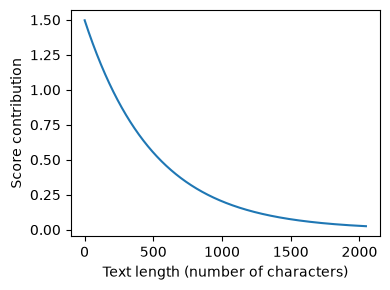

In [95]:
import matplotlib.pyplot as plt

def plot_brevity_curve(brevity_bonus, max_len=2048):
    lengths = torch.arange(1, max_len)
    scores = 1.5 * torch.exp(-lengths / brevity_bonus)

    plt.figure(figsize=(4, 3))
    plt.plot(lengths, scores)
    plt.xlabel("Text length (number of characters)")
    plt.ylabel("Score contribution")
    plt.tight_layout()
    #plt.savefig("brevity_curve.pdf")
    plt.show()

plot_brevity_curve(500)

In [96]:
print(round(heuristic_score(response_1), 3))

2.13


In [97]:
print(round(heuristic_score(response_2), 3))

2.256


In [98]:
@torch.inference_mode()
def calc_next_token_probas(model, tokenizer, prompt, device, show=True):

    token_ids = torch.tensor(tokenizer.encode(prompt), device=device)

    logits = model(token_ids.unsqueeze(0)).squeeze(0)
    all_probas = torch.softmax(logits, dim=-1)

    t_idx = torch.arange(0, token_ids.shape[0] - 1, device=device)

    next_ids = token_ids[1:]

    next_token_probas = all_probas[t_idx, next_ids]

    prod_next_token_probas = torch.prod(next_token_probas)

    if show:
        print("Next-token probabilities:", next_token_probas)
        print("Joint probability:", prod_next_token_probas)

    else:
        return next_token_probas, prod_next_token_probas

In [99]:
torch.set_printoptions(precision=4, sci_mode=True)

In [100]:
calc_next_token_probas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Berlin"
    )

Next-token probabilities: tensor([5.7936e-05, 4.5117e-01, 1.6235e-02, 7.2656e-01, 1.6211e-01],
       device='mps:0', dtype=torch.bfloat16)
Joint probability: tensor(5.0059e-08, device='mps:0', dtype=torch.bfloat16)


In [101]:
calc_next_token_probas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Bridge"
    )

Next-token probabilities: tensor([5.7936e-05, 4.5117e-01, 1.6235e-02, 7.2656e-01, 3.0361e-07],
       device='mps:0', dtype=torch.bfloat16)
Joint probability: tensor(9.3703e-14, device='mps:0', dtype=torch.bfloat16)


In [102]:
calc_next_token_probas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Hamburg"
    )

Next-token probabilities: tensor([5.7936e-05, 4.5117e-01, 1.6235e-02, 7.2656e-01, 3.1982e-02],
       device='mps:0', dtype=torch.bfloat16)
Joint probability: tensor(9.8371e-09, device='mps:0', dtype=torch.bfloat16)


In [103]:
torch.set_printoptions(precision=4, sci_mode=False)

In [105]:
logits = torch.linspace(-2, 2, steps=7)
print(logits)
probas = torch.softmax(logits, dim=-1)
print(probas)

tensor([-2.0000, -1.3333, -0.6667, -0.0000,  0.6667,  1.3333,  2.0000])
tensor([0.0090, 0.0175, 0.0341, 0.0665, 0.1295, 0.2522, 0.4912])


In [106]:
print(torch.log(probas))

tensor([-4.7109, -4.0442, -3.3776, -2.7109, -2.0442, -1.3776, -0.7109])


In [107]:
log_probas = torch.log_softmax(logits, dim=-1)
print(log_probas)

tensor([-4.7109, -4.0442, -3.3776, -2.7109, -2.0442, -1.3776, -0.7109])


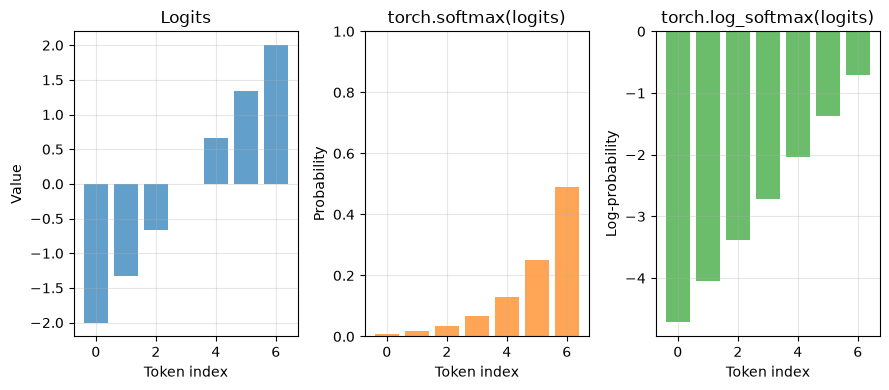

In [108]:
plt.figure(figsize=(9, 4))

# Logits
plt.subplot(1, 3, 1)
plt.bar(range(len(logits)), logits, color="C0", alpha=0.7)
plt.title("Logits")
plt.xlabel("Token index")
plt.ylabel("Value")
plt.grid(alpha=0.3)

# Softmax
plt.subplot(1, 3, 2)
plt.bar(range(len(probas)), probas, color="C1", alpha=0.7)
plt.title("torch.softmax(logits)")
plt.xlabel("Token index")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.grid(alpha=0.3)

# Log-softmax
plt.subplot(1, 3, 3)
plt.bar(range(len(log_probas)), log_probas, color="C2", alpha=0.7)
plt.title("torch.log_softmax(logits)")
plt.xlabel("Token index")
plt.ylabel("Log-probability")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("logits_softmax_log_softmax.pdf")
plt.show()

In [109]:
@torch.inference_mode()
def calc_next_token_logprobas(model, tokenizer, prompt, device, show=True):

    token_ids = torch.tensor(tokenizer.encode(prompt), device=device)

    logits = model(token_ids.unsqueeze(0)).squeeze(0)
    # We now use log_softmax
    all_logprobas = torch.log_softmax(logits, dim=-1)

    t_idx = torch.arange(0, token_ids.shape[0] - 1, device=device)
    next_ids = token_ids[1:]
    next_token_logprobas = all_logprobas[t_idx, next_ids]

    # We replace the product with a sum
    sum_next_token_logprobas = torch.sum(next_token_logprobas)

    if show:
        print("Next-token log-probabilities:", next_token_logprobas)
        print("Joint log-probability:", sum_next_token_logprobas)
    else:
        return next_token_logprobas, sum_next_token_logprobas

In [110]:
calc_next_token_logprobas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Berlin"
    )

Next-token log-probabilities: tensor([-9.7500, -0.7930, -4.1250, -0.3203, -1.8203], device='mps:0',
       dtype=torch.bfloat16)
Joint log-probability: tensor(-16.7500, device='mps:0', dtype=torch.bfloat16)


In [111]:
calc_next_token_logprobas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Bridge"
    )

Next-token log-probabilities: tensor([ -9.7500,  -0.7930,  -4.1250,  -0.3203, -15.0000], device='mps:0',
       dtype=torch.bfloat16)
Joint log-probability: tensor(-30., device='mps:0', dtype=torch.bfloat16)


In [112]:
calc_next_token_logprobas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Hamburg"
    )

Next-token log-probabilities: tensor([-9.7500, -0.7930, -4.1250, -0.3203, -3.4375], device='mps:0',
       dtype=torch.bfloat16)
Joint log-probability: tensor(-18.3750, device='mps:0', dtype=torch.bfloat16)


In [113]:
example_prompt = "What is the captial of Germany?"
example_answer = "The captial of Germany is Berlin."

next_token_logprobas, sum_next_token_logprobas = calc_next_token_logprobas(
    model, tokenizer, device=device,
    prompt=example_prompt+example_answer,
    show=False
)

print("Next-token logprobas:", next_token_logprobas)
print("Joint log-probability:", sum_next_token_logprobas)

Next-token logprobas: tensor([ -0.4512,  -0.3262, -14.6875,  -1.3672,  -4.3750,  -5.1875,  -2.2812,
         -6.7500,  -5.8750,  -0.0156,  -0.0498,  -0.0933,  -0.1221,  -0.5742,
         -0.5977], device='mps:0', dtype=torch.bfloat16)
Joint log-probability: tensor(-42.7500, device='mps:0', dtype=torch.bfloat16)


In [114]:
print(len(tokenizer.encode(example_answer)))

8


In [118]:
last_8 = next_token_logprobas[-8:]
print(last_8)

tensor([-6.7500, -5.8750, -0.0156, -0.0498, -0.0933, -0.1221, -0.5742, -0.5977],
       device='mps:0', dtype=torch.bfloat16)


In [119]:
print(torch.mean(last_8))

tensor(-1.7578, device='mps:0', dtype=torch.bfloat16)


In [127]:
@torch.inference_mode()
def avg_logprob_answer(model, tokenizer, prompt, answer, device="cpu"):
    prompt_ids = tokenizer.encode(prompt)
    answer_ids = tokenizer.encode(answer)
    full_ids = torch.tensor(prompt_ids + answer_ids, device=device)

    logits = model(full_ids.unsqueeze(0)).squeeze(0)
    logprobas = torch.log_softmax(logits, dim=-1)

    start = len(prompt_ids) - 1
    end = full_ids.shape[0] - 1

    # Same as before, except for using start and end
    t_idx = torch.arange(start, end, device=device)
    next_tokens = full_ids[start + 1 : end + 1]
    next_token_logps = logprobas[t_idx, next_tokens]

    # Average over the answer token scores
    return torch.mean(next_token_logps).item()

In [128]:
score_1 = avg_logprob_answer(
    model, tokenizer,
    prompt="What is the capital of Germany?",
    answer=" The capital of Germany is Berlin.",
    device=device
)
print(score_1)

-0.19921875


In [129]:
score_2 = avg_logprob_answer(
    model, tokenizer,
    prompt="What is the capital of Germany?",
    answer=" The capital of Germany is Bridge.",
    device=device
)
print(score_2)

-3.859375


In [130]:
avg_logprob_answer(
    model, tokenizer,
    prompt=prompt_cot,
    answer=response_1,
    device=device
)

-0.0654296875

In [131]:
avg_logprob_answer(
    model, tokenizer,
    prompt=prompt_cot,
    answer=response_2,
    device=device
)

-0.119140625

In [139]:
raw_prompt = (
    "Half the value of $3x-9$ is $x+37$. "
    "What is the value of $x$?"
)

prompt = render_prompt(raw_prompt)
torch.manual_seed(123)
initial_response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device, 
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.7, top_p=0.9
)

 \boxed{18}

In [140]:
def make_critique_prompt(raw_prompt, draft):
    return (
        "You are a meticulous reviewer. Identify logical errors, missing "
        "steps, or arithmetic mistakes. If the answer seems correct, "
        "say so briefly. Then propose a concise plan to fix issues.\n\n"
        f"Question:\n{raw_prompt}\n\n"
        f"Draft answer:\n{draft}\n\n"
        "Write a short critique and bullet-point fix plan "
        "(under ~120 words).\n"
        "Critique:"
    )


critique_prompt = make_critique_prompt(raw_prompt, intial_response)
print("Critique Prompt : ",critique_prompt)

Critique Prompt :  You are a meticulous reviewer. Identify logical errors, missing steps, or arithmetic mistakes. If the answer seems correct, say so briefly. Then propose a concise plan to fix issues.

Question:
Half the value of $3x-9$ is $x+37$. What is the value of $x$?

Draft answer:
 \boxed{18}

Write a short critique and bullet-point fix plan (under ~120 words).
Critique:


In [141]:
torch.manual_seed(123)
critique = generate_text_stream_concat_flex(
    model, tokenizer, critique_prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.7,
    top_p=0.9, 
)

 The solution is incomplete. The equation is not properly solved.

Fix plan: 1. Start with the equation: $3x - 9 = 2(x + 37)$
2. Distribute 2 on the right side: $3x - 9 = 2x + 74$
3. Subtract $2x$ from both sides: $x - 9 = 74$
4. Add 9 to both sides: $x = 83$
5. Check the solution: $3(83) - 9 = 2(83 + 37)$

In [142]:
def make_refine_prompt(raw_prompt, draft, critique):
    return (
        "Revise the answer using the critique. Keep it concise and "
        "end with a final boxed result: \\boxed{ANSWER}\n\n"
        f"Question:\n{raw_prompt}\n\n"
        f"Previous answer:\n{draft}\n\n"
        f"Critique:\n{critique}\n\n"
        "Revised answer:"
    )

refine_prompt = make_refine_prompt(raw_prompt, initial_response, critique)
print(refine_prompt)

Revise the answer using the critique. Keep it concise and end with a final boxed result: \boxed{ANSWER}

Question:
Half the value of $3x-9$ is $x+37$. What is the value of $x$?

Previous answer:
 \boxed{18}

Critique:
 The solution is incomplete. The equation is not properly solved.

Fix plan: 1. Start with the equation: $3x - 9 = 2(x + 37)$
2. Distribute 2 on the right side: $3x - 9 = 2x + 74$
3. Subtract $2x$ from both sides: $x - 9 = 74$
4. Add 9 to both sides: $x = 83$
5. Check the solution: $3(83) - 9 = 2(83 + 37)$

Revised answer:


In [143]:
def make_refine_prompt(raw_prompt, draft, critique):
    return (
        "Revise the answer using the critique. Keep it concise and "
        "end with a final boxed result: \\boxed{ANSWER}\n\n"
        f"Question:\n{raw_prompt}\n\n"
        f"Previous answer:\n{draft}\n\n"
        f"Critique:\n{critique}\n\n"
        "Revised answer:"
    )

refine_prompt = make_refine_prompt(raw_prompt, initial_response, critique)
torch.manual_seed(123)
revised_answer = generate_text_stream_concat_flex(
    model, tokenizer, refine_prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.7,
    top_p=0.9, 
)

 \boxed{83}

Answer:
 \boxed{83}

In [147]:
def self_refinement_loop(
    model,
    tokenizer,
    raw_prompt,
    device,
    iterations=2,
    max_response_tokens=2048,
    max_critique_tokens=256,
    score_fn=None,
    prompt_renderer=render_prompt,
    prompt_suffix="",
    verbose=False,
    temperature=0.7,
    top_p=0.9,
):
    steps = []

    # 1. Prepare the original prompt
    prompt = prompt_renderer(raw_prompt) + prompt_suffix

    # 2. Generate the initial answer
    current_full = generate_text_stream_concat_flex(
        model=model, tokenizer=tokenizer, prompt=prompt, device=device,
        max_new_tokens=max_response_tokens, verbose=False,
        generate_func=generate_text_top_p_stream_cache,
        temperature=temperature, top_p=top_p,
    )
    current_extracted = extract_final_candidate(current_full, fallback="number_then_full")
    current_score = score_fn(answer=current_full, prompt=prompt) if score_fn else 0.0

    for it in range(iterations):
        draft_before_full = current_full
        draft_before_extracted = current_extracted
        score_before = current_score

        # 3. Critique the draft
        critique_full = generate_text_stream_concat_flex(
            model=model, tokenizer=tokenizer,
            prompt=make_critique_prompt(raw_prompt, draft_before_full),
            device=device, max_new_tokens=max_critique_tokens, verbose=False,
            generate_func=generate_text_top_p_stream_cache,
            temperature=temperature, top_p=top_p,
        )

        # 4. Refine using the critique
        revised_full = generate_text_stream_concat_flex(
            model=model, tokenizer=tokenizer,
            prompt=make_refine_prompt(raw_prompt, draft_before_full, critique_full),
            device=device, max_new_tokens=max_response_tokens, verbose=False,
            generate_func=generate_text_top_p_stream_cache,
            temperature=temperature, top_p=top_p,
        )
        revised_extracted = extract_final_candidate(revised_full, fallback="number_then_full")
        revised_score = score_fn(answer=revised_full, prompt=prompt) if score_fn else 0.0

        steps.append({
            "iteration": it + 1,
            "draft_full": draft_before_full,
            "draft_extracted": draft_before_extracted,
            "critique": critique_full,
            "revised_full": revised_full,
            "revised_extracted": revised_extracted,
            "score_before": score_before,
            "score_after": revised_score,
        })

        if verbose:
            print(
                f"[Refinement {it+1}/{iterations}]"
                f"\nCurrent: {draft_before_extracted}"
                f"\nRevised: {revised_extracted}"
                f"\nScore before: {score_before:.3f}"
                f"\nScore after: {revised_score:.3f}"
                f"\n{'=' * 25}"
            )

        # 5. Keep the revision if it's not worse
        if revised_score >= current_score:
            current_full = revised_full
            current_extracted = revised_extracted
            current_score = revised_score

    return {
        "final_full": current_full,
        "final_extracted": current_extracted,
        "steps": steps,
    }


In [148]:
from functools import partial

avg_logprob_score = partial(
    avg_logprob_answer,
    model=model,
    tokenizer=tokenizer,
    device=device
)

In [149]:
torch.manual_seed(1)

results_logprob = self_refinement_loop(
    model=model,
    tokenizer=tokenizer,
    raw_prompt=raw_prompt,
    device=device,
    iterations=2,
    max_response_tokens=2048,
    max_critique_tokens=256,
    score_fn=avg_logprob_score,
    verbose=True,
    temperature=0.7,
    top_p=0.9,
)

[Refinement 1/2]
Current: 10
Revised: 9
Score before: -0.863
Score after: -0.338
[Refinement 2/2]
Current: 9
Revised: 9
Score before: -0.338
Score after: -1.508


In [150]:
print(results_logprob["final_extracted"])

9
